# DBSCAN: Customer Segmentation


**How DBSCAN works:** a customer is a *core point* if it has at least `min_samples` neighbours within distance `eps`.
Core points that are close to each other join one cluster. Points that are not close to any dense area are labelled **noise (-1)**.
So DBSCAN does not need the number of clusters in advance, and it can leave strange customers out instead of forcing them into a group.



## 1. Setup and loading the data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

BASE = "../data/processed/"   # notebook inside dbscan/ after git clone
# BASE = "https://raw.githubusercontent.com/JanaAlzobidi/Machine-Learning-Projects/main/Unit-5-Unsupervised-Learning/customer-segmentation-clustering/data/processed/"  # Google Colab

Z = pd.read_csv(BASE + "customer_pca.csv", index_col="CustomerID")                       #cluster this
info = pd.read_csv(BASE + "customer_features.csv", index_col="CustomerID").loc[Z.index]   #describe clusters with this
A = pd.read_csv(BASE + "customer_pca_all.csv", index_col="CustomerID")                   #noise test
P = A.drop(columns="IsOutlier")

print("Z (to cluster):", Z.shape)
print("A (with outliers):", A.shape, "| outliers:", A["IsOutlier"].sum())
Z.head()

Z (to cluster): (4143, 5)
A (with outliers): (4362, 6) | outliers: 219


,PC1,PC2,PC3,PC4,PC5
CustomerID,,,,,
12346,-2.734894,-2.991986,2.132441,0.998034,0.468937
12347,3.589612,2.281717,-1.242719,-0.382392,-0.807583
12348,1.228287,0.845236,-0.985068,-0.459783,0.898431
12349,0.553772,5.872273,1.939445,0.008892,-0.733261
12350,-2.660162,0.845008,0.680010,0.214199,0.409236


## 2. Choosing `min_samples`
A common rule is `min_samples = 2 x number of dimensions`. We have 5 PCA components, so **min_samples = 10**.

In [2]:
MIN_SAMPLES = 10

## 3. Choosing `eps` with the k-distance plot
For every customer we measure the distance to its 10th nearest neighbour and sort these distances.
Most customers sit in dense areas (small distance). Where the curve bends sharply upward, points start to be isolated.
That bend is a good value for `eps`.

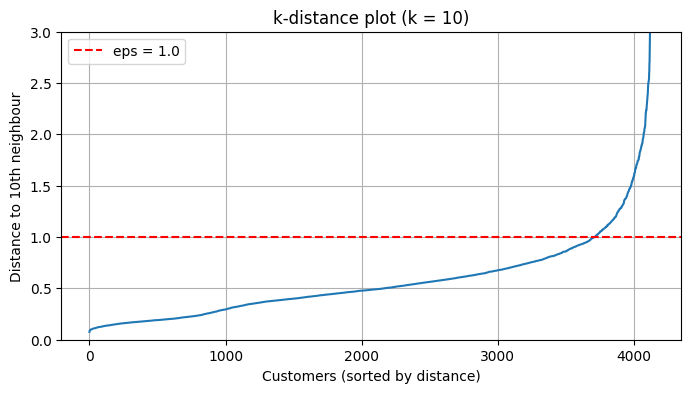

Percentiles of the 10th-neighbour distance:
  50%: 0.49
  80%: 0.78
  90%: 1.02
  95%: 1.37


In [3]:
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z)
dist, _ = nn.kneighbors(Z)
k_dist = np.sort(dist[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_dist)
plt.axhline(1.0, color="red", linestyle="--", label="eps = 1.0")
plt.xlabel("Customers (sorted by distance)")
plt.ylabel("Distance to 10th neighbour")
plt.title("k-distance plot (k = 10)")
plt.ylim(0, 3)
plt.legend()
plt.grid(True)
plt.show()

print("Percentiles of the 10th-neighbour distance:")
for p in [50, 80, 90, 95]:
    print(f"  {p}%: {np.percentile(k_dist, p):.2f}")

The curve stays flat until about 0.8 and starts climbing steeply around **1.0** (roughly the 90th percentile).
Before choosing, we check how sensitive DBSCAN is to `eps`.

## 4. Sensitivity to `eps`

In [4]:
rows = []
for eps in [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.2]:
    labels = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(Z)
    mask = labels != -1
    n_clusters = len(set(labels[mask]))
    sil = silhouette_score(Z[mask], labels[mask]) if n_clusters > 1 else np.nan
    rows.append({"eps": eps,
                 "clusters": n_clusters,
                 "noise %": round((~mask).mean() * 100, 1),
                 "silhouette (no noise)": round(sil, 3)})

sens = pd.DataFrame(rows)
sens

,eps,clusters,noise %,silhouette (no noise)
0,0.4,11,52.4,0.438
1,0.5,6,33.5,0.279
2,0.6,5,22.7,0.409
3,0.7,3,15.9,0.305
4,0.8,5,10.8,0.142
5,0.9,3,7.6,0.323
6,1.0,4,5.5,0.302
7,1.2,2,3.5,0.350


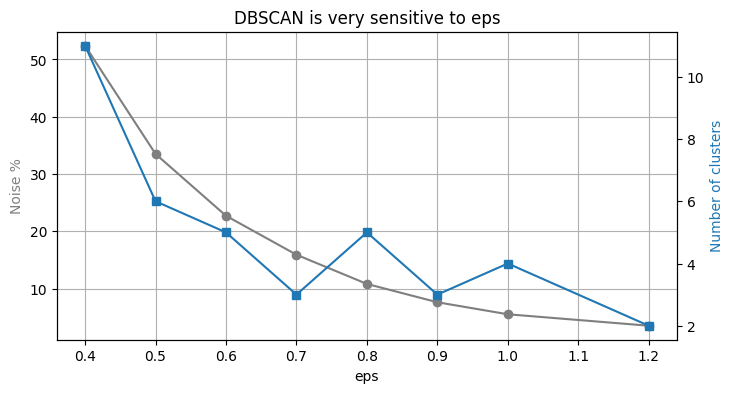

In [5]:
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(sens["eps"], sens["noise %"], marker="o", color="tab:gray")
ax1.set_xlabel("eps")
ax1.set_ylabel("Noise %", color="tab:gray")
ax2 = ax1.twinx()
ax2.plot(sens["eps"], sens["clusters"], marker="s", color="tab:blue")
ax2.set_ylabel("Number of clusters", color="tab:blue")
plt.title("DBSCAN is very sensitive to eps")
ax1.grid(True)
plt.show()

**What this shows:** a small change in `eps` changes the result a lot. At `eps = 0.4` about half of the customers are noise; at `eps = 1.0` only about 5%.
Small `eps` values also create many tiny clusters of 10-60 customers.

**Choice: `eps = 1.0`.** It sits at the bend of the k-distance plot, and it labels about 5% of customers as noise,
which is a realistic share of unusual customers. Smaller values throw away too many normal customers as noise.

## 5. Final model

In [6]:
EPS = 1.0
db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(Z)
labels = db.labels_

mask = labels != -1
n_clusters = len(set(labels[mask]))
noise_share = (~mask).mean()

print(f"eps = {EPS}, min_samples = {MIN_SAMPLES}")
print(f"Number of clusters: {n_clusters}")
print(f"Noise points: {(~mask).sum()} ({noise_share:.1%})")
print()
print("Cluster sizes:")
print(pd.Series(labels).value_counts().sort_index().rename({-1: "noise (-1)"}))

eps = 1.0, min_samples = 10
Number of clusters: 4
Noise points: 229 (5.5%)

Cluster sizes:
noise (-1)     229
0             1219
1             2667
2               18
3               10
Name: count, dtype: int64


## 6. Evaluation
Silhouette and Davies-Bouldin are computed **without the noise points**, because noise is not a cluster.
Dropping noise makes the scores look better, so the noise share is always reported next to them.

In [7]:
sil = silhouette_score(Z[mask], labels[mask])
dbi = davies_bouldin_score(Z[mask], labels[mask])

print(f"Silhouette (no noise):     {sil:.3f}   (higher is better)")
print(f"Davies-Bouldin (no noise): {dbi:.3f}   (lower is better)")
print(f"Noise share:               {noise_share:.1%}")

Silhouette (no noise):     0.302   (higher is better)
Davies-Bouldin (no noise): 0.886   (lower is better)
Noise share:               5.5%


## 7. Clusters on PC1 vs PC2 (noise in grey)

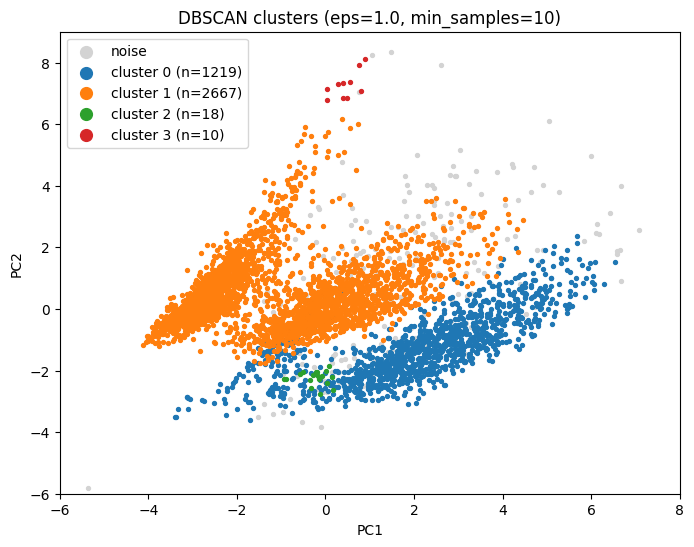

In [8]:
plt.figure(figsize=(8, 6))
plt.scatter(Z.loc[~mask, "PC1"], Z.loc[~mask, "PC2"], c="lightgrey", s=8, label="noise")
for c in sorted(set(labels[mask])):
    pts = labels == c
    plt.scatter(Z.loc[pts, "PC1"], Z.loc[pts, "PC2"], s=8, label=f"cluster {c} (n={pts.sum()})")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"DBSCAN clusters (eps={EPS}, min_samples={MIN_SAMPLES})")
plt.xlim(-6, 8); plt.ylim(-6, 9)   # zoom on the main cloud (a few far-away noise points are outside)
plt.legend(markerscale=3)
plt.show()

**Cluster shape:** DBSCAN finds two large dense groups that touch each other: cluster 1 on the left/upper side (low PC1) and cluster 0 on the right/lower side (high PC1, lower PC2), plus two very small groups.
It does not split the big groups further, because inside each group the density is continuous (no empty gap between sub-groups).
Noise points sit on the edges of the cloud, where customers are spread out.

## 8. Cluster profiles

In [9]:
features = ["Recency_Days", "N_Invoices", "Total_Spend", "Unique_Products",
            "Avg_Invoice_Value", "N_Cancellations", "Spend_Trend"]

prof = info[features].copy()
prof["cluster"] = labels
summary = prof.groupby("cluster")[features].median().round(1)
summary.insert(0, "customers", prof["cluster"].value_counts().sort_index())
summary.insert(1, "share of spend %",
               (prof.groupby("cluster")["Total_Spend"].sum() / prof["Total_Spend"].sum() * 100).round(1))
summary

,customers,share of spend %,Recency_Days,N_Invoices,Total_Spend,Unique_Products,Avg_Invoice_Value,N_Cancellations,Spend_Trend
cluster,,,,,,,,,
-1,229,10.4,39.0,3.0,1310.5,53.0,447.8,1.0,-52.2
0,1219,48.9,26.0,6.0,1336.4,61.0,204.6,1.0,0.0
1,2667,40.1,65.0,2.0,406.5,26.0,233.4,0.0,0.0
2,18,0.1,65.0,2.0,315.8,19.0,151.5,1.0,-334.2
3,10,0.4,99.0,1.0,1806.9,28.5,1806.9,0.0,0.0


In [10]:
# Names given after reading the medians above
names = {-1: "Noise / unusual customers",
          0: "Active repeat buyers",
          1: "Occasional small buyers",
          2: "Small buyers who cancel and are slowing down",
          3: "One-time big basket"}
summary.insert(0, "name", [names.get(c, "") for c in summary.index])
summary[["name", "customers", "share of spend %"]]

,name,customers,share of spend %
cluster,,,
-1,Noise / unusual customers,229,10.4
0,Active repeat buyers,1219,48.9
1,Occasional small buyers,2667,40.1
2,Small buyers who cancel and are slowing down,18,0.1
3,One-time big basket,10,0.4


**Reading the profiles (medians):**
- **Cluster 0, Active repeat buyers** (about 29% of customers, about 49% of spend): about 6 invoices, bought recently (about 26 days ago), many different products. The most valuable group.
- **Cluster 1, Occasional small buyers** (about 64% of customers, about 40% of spend): about 2 invoices, last purchase about 2 months ago, low total spend. The large "normal" mass of customers.
- **Cluster 2, Small buyers who cancel and are slowing down** (18 customers): low spend, half of their orders cancelled, and a strongly falling spend trend.
- **Cluster 3, One-time big basket** (10 customers): a single large order (about 1,800) and no return since.
- **Noise** (about 5.5%, about 10% of spend): customers that don't fit a dense group. Their average invoice is about twice as large as in the clusters, so many are unusual big or irregular buyers, worth checking one by one.

Clusters 2 and 3 are very small. DBSCAN creates them because they are tiny dense pockets; in practice they behave more like special cases than real segments.

## 9. Noise test: does DBSCAN find the extreme customers by itself?
During preparation, Isolation Forest set aside the 5% most extreme customers (219). The main file does not include them, which hides DBSCAN's main strength.
Here we run DBSCAN with the **same settings** on all 4,362 customers and check how many of those 219 it labels as noise on its own.

In [11]:
labels_all = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(P)
is_out = A["IsOutlier"].values

caught = (labels_all[is_out] == -1).mean()
regular_noise = (labels_all[~is_out] == -1).mean()

print(f"Extreme customers labelled as noise:  {caught:.1%}  ({(labels_all[is_out] == -1).sum()} of {is_out.sum()})")
print(f"Regular customers labelled as noise:  {regular_noise:.1%}")
print(f"Clusters found: {len(set(labels_all[labels_all != -1]))}")

Extreme customers labelled as noise:  72.6%  (159 of 219)
Regular customers labelled as noise:  5.5%
Clusters found: 4


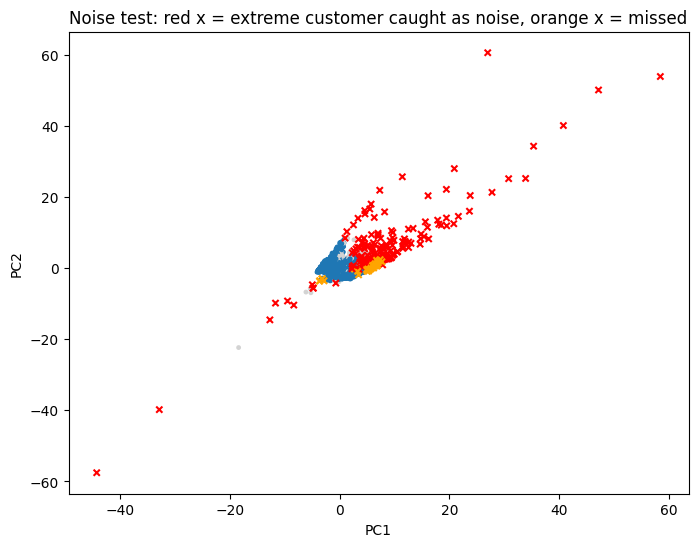

In [12]:
plt.figure(figsize=(8, 6))
plt.scatter(P.loc[~is_out, "PC1"], P.loc[~is_out, "PC2"], c=np.where(labels_all[~is_out] == -1, "lightgrey", "tab:blue"), s=6)
plt.scatter(P.loc[is_out, "PC1"], P.loc[is_out, "PC2"],
            c=np.where(labels_all[is_out] == -1, "red", "orange"), s=20, marker="x")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Noise test: red x = extreme customer caught as noise, orange x = missed")
plt.show()

In [13]:
# How the result changes with eps (same as section 4, but on the full data)
rows = []
for eps in [0.6, 0.8, 1.0, 1.2]:
    la = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(P)
    rows.append({"eps": eps,
                 "extreme caught %": round((la[is_out] == -1).mean() * 100, 1),
                 "regular as noise %": round((la[~is_out] == -1).mean() * 100, 1)})
pd.DataFrame(rows)

,eps,extreme caught %,regular as noise %
0,0.6,92.7,22.3
1,0.8,81.7,10.5
2,1.0,72.6,5.5
3,1.2,62.1,3.5


**Result:** with the same settings, DBSCAN labels about **73% of the extreme customers as noise by itself**, while only about 5.5% of regular customers become noise.
In the plot, every far-away extreme customer is caught; the ones DBSCAN misses (orange) sit at the edge of the main cloud, close to normal customers.
The two main clusters stay the same. Extreme customers do not pull them, because DBSCAN simply leaves those customers out.

There is a trade-off: a smaller `eps` catches more extreme customers (about 93% at eps 0.6) but also labels many normal customers as noise (about 22%).
This is DBSCAN's main strength compared with K-Means and GMM, which must put every customer in some cluster.

## 10. Strengths, weaknesses and when to use DBSCAN

| | |
|---|---|
| **Strengths** | No need to choose the number of clusters. Detects outliers by itself (noise = -1). Can find clusters of any shape. The clusters do not change if the extreme customers are added, because they become noise instead of pulling the clusters. |
| **Weaknesses** | Very sensitive to `eps` (noise goes from about 50% to 5% between eps 0.4 and 1.0). One `eps` for the whole data, so it struggles when groups have different densities. On this data it finds only 2 large groups, because the customer segments touch each other with no low-density gap. Silhouette must exclude noise. |
| **When to use** | When you expect outliers or noise, when clusters have irregular shapes, when the number of clusters is unknown, or when finding unusual customers (fraud, VIPs, data errors) is part of the goal. Not the best choice when segments overlap and you need several balanced marketing groups. |

## 11. Key insights

1. **DBSCAN finds 2 main segments** on this data (active repeat buyers vs occasional small buyers) plus 2 tiny groups and 5.5% noise, with eps = 1.0 and min_samples = 10.
2. **Scores:** silhouette 0.30 and Davies-Bouldin 0.89 (both without noise, noise share 5.5%).
3. **Very sensitive to `eps`:** noise falls from 52% to 5.5% between eps 0.4 and 1.0, and the number of clusters jumps between 2 and 11.
4. **Best at outliers:** it flags about 73% of the extreme customers as noise on its own, which K-Means and GMM cannot do.
5. **Not ideal for detailed marketing segments:** customer groups here touch each other without empty gaps, so DBSCAN merges them into a few big groups. For several balanced segments, K-Means or GMM is more useful; DBSCAN is a good tool for finding the unusual customers first.

## 12. Save the labels

In [14]:
np.save("labels_dbscan.npy", labels)   # same row order as customer_pca.csv, noise stays -1
print("Saved labels_dbscan.npy:", labels.shape, "| unique labels:", sorted(set(labels)))

Saved labels_dbscan.npy: (4143,) | unique labels: [np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
